# Examples of Unitaries Evolutions

In [1]:
%reload_ext autoreload

import numpy as np 
import matplotlib.pyplot as plt
import math as math 
import cmath as cmath
from scipy import linalg as linalg
from scipy import integrate as integ
from scipy.integrate import solve_ivp



import sys
import os
sys.path.append(os.path.abspath('../src'))

from Objects import Quantum_State, Hamiltonian,Decoherence, Symplectic
from QIT_Functions import Extract_Qubit_Labels_Array


## Gaussian Unitary Dynamics: 
## Coherent State in a Quantum Harmonic Oscillator 

### Semi-Analytical

This is a time independent gaussian Hamiltonian
Initializing a Gaussian State


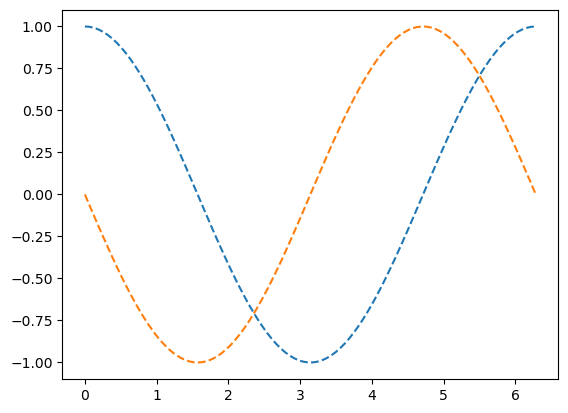

In [2]:
N_qubits = 1
n_modes = 1

########################## Hamiltonians ##########################

H_1_general = Hamiltonian(N_qubits, n_modes)
H_1_force = Hamiltonian(N_qubits, n_modes)
H_1_gauss = Hamiltonian(N_qubits, n_modes)

H_null = np.zeros((2*n_modes,2*n_modes)) 
iden = np.eye(2*n_modes)
r_null = np.zeros((2*n_modes,1)) 

H_m = np.eye(2)
r_m = r_null
H_q = H_null
r_q = r_null

H_q_0_array = np.array([0 +0*1j])

H_1_gauss.Initialize_Constant_Hamiltonians([H_m], [r_m], H_q_0_array)

########################## Initialize State ##########################

r_0 = np.array([[1.0],
                [0.0]])
sigma_0 = iden
rho_q_0 = np.ones((2*N_qubits,2*N_qubits))/(2**(2*N_qubits))

Gaussian_State = Quantum_State(N_qubits, n_modes)
Gaussian_State.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)

########################## Dynamics ##########################

t_array = np.linspace(0,2*np.pi, 100)
Gaussian_State.Unitary_Dynamics_Numerical(H_1_gauss, t_array)

plt.plot(t_array,Gaussian_State.r_t[:,0], '--')
plt.plot(t_array,Gaussian_State.r_t[:,1], '--');

### Analytical

This is a time independent gaussian Hamiltonian
Initializing a Gaussian State


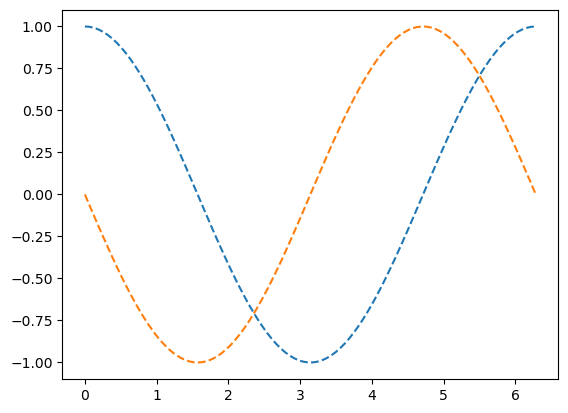

In [3]:
N_qubits = 1
n_modes = 1

omega = 1

########################## Hamiltonians ##########################

H_1_gauss = Hamiltonian(N_qubits, n_modes)
H_1_force = Hamiltonian(N_qubits, n_modes)

H_null = np.zeros((2*n_modes,2*n_modes)) 
iden = np.eye(2*n_modes)
r_null = np.zeros((2*n_modes,1)) 

H_m = omega*np.eye(2)
r_m = r_null
H_q = H_null
r_q = np.array([[0.0],[0.0]])

H_q_0_array = np.array([0 +0*1j])

H_1_gauss.Initialize_Constant_Hamiltonians([H_m], [r_m], H_q_0_array)

########################## Initialize State ##########################

r_0 = np.array([[1.0],
                [0.0]])
sigma_0 = iden
rho_q_0 = np.ones((2*N_qubits,2*N_qubits))/(2**(2*N_qubits))

Gaussian_State = Quantum_State(N_qubits, n_modes)
Gaussian_State.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)

########################## Initialize Sympeltic Methods ##########################

Symp_QHO_1 = Symplectic(N_qubits, n_modes)

symplectic_name = "QHO_1"
symplectic_parameters = omega

Symp_QHO_1.Initialize_Constant_Symplectic(symplectic_name, symplectic_parameters)

t_array = np.linspace(0,2*np.pi, 100)

Gaussian_State.Unitary_Dynamics_Analytical(H_1_gauss, Symp_QHO_1, t_array)

########################## Plot First Moments ##########################


plt.plot(t_array,Gaussian_State.r_t[:,0], '--')
plt.plot(t_array,Gaussian_State.r_t[:,1], '--')


## Linear Qubit-Mode Interaction: 
## Stern-Gerlach Interfereometry

### Semi-Analytical

In [4]:
N_qubits = 1
n_modes = 1

########################## Hamiltonians ##########################

H_1_general = Hamiltonian(N_qubits, n_modes)
H_1_force = Hamiltonian(N_qubits, n_modes)

H_null = np.zeros((2*n_modes,2*n_modes)) 
iden = np.eye(2*n_modes)
r_null = np.zeros((2*n_modes,1)) 

H_m = np.eye(2)
r_m =  1*np.array([[1.0],[0.0]]) #np.array([[0.5],[0.0]])
H_q = H_null
r_q = 2*np.array([[1.0],[0.0]])

H_q_0_array = np.array([0 +0*1j])

H_1_force.Initialize_Constant_Hamiltonians([H_m], [r_m, r_q], H_q_0_array)

########################## Initialize State ##########################

r_0 = np.array([[0.0],
                [0.0]])
sigma_0 = iden
rho_q_0 = np.ones((2*N_qubits,2*N_qubits))/(2**(2*N_qubits))

GCS = Quantum_State(N_qubits, n_modes)
GCS.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)

########################## Dynamics ##########################

t_array = np.linspace(0,2*np.pi, 100)

GCS.Unitary_Dynamics_Numerical(H_1_force, t_array)

print(np.shape(GCS.r_JK_t))

t_idx = 50   # pick a mid-point in time

for j in range(2):
    for k in range(2):
        v = GCS.r_JK_t[t_idx, j, k, :, 0]
        print(f"r_JK_t[{j},{k}] = {v}")


This is a time independent operator-valued force Hamiltonian
Initializing a Gaussian State
(100, 2, 2, 2, 1)
r_JK_t[0,0] = [-1.99949654+0.j  0.03172793+0.j]
r_JK_t[0,1] = [ 1.99949654+0.06345587j -0.03172793+3.99899308j]
r_JK_t[1,0] = [ 1.99949654-0.06345587j -0.03172793-3.99899308j]
r_JK_t[1,1] = [ 5.99848963-7.01957039e-34j -0.0951838 +2.22044605e-16j]


Parameter_list = []
array_pi = np.linspace(0,2,5)

GCS.Plot_Phase_Space_First_QRDM(Parameter_list, array_pi, False);

### Analytical (with Unknown Force)

This is a time independent operator-valued force Hamiltonian
Initializing a Gaussian State


/opt/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/opt/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


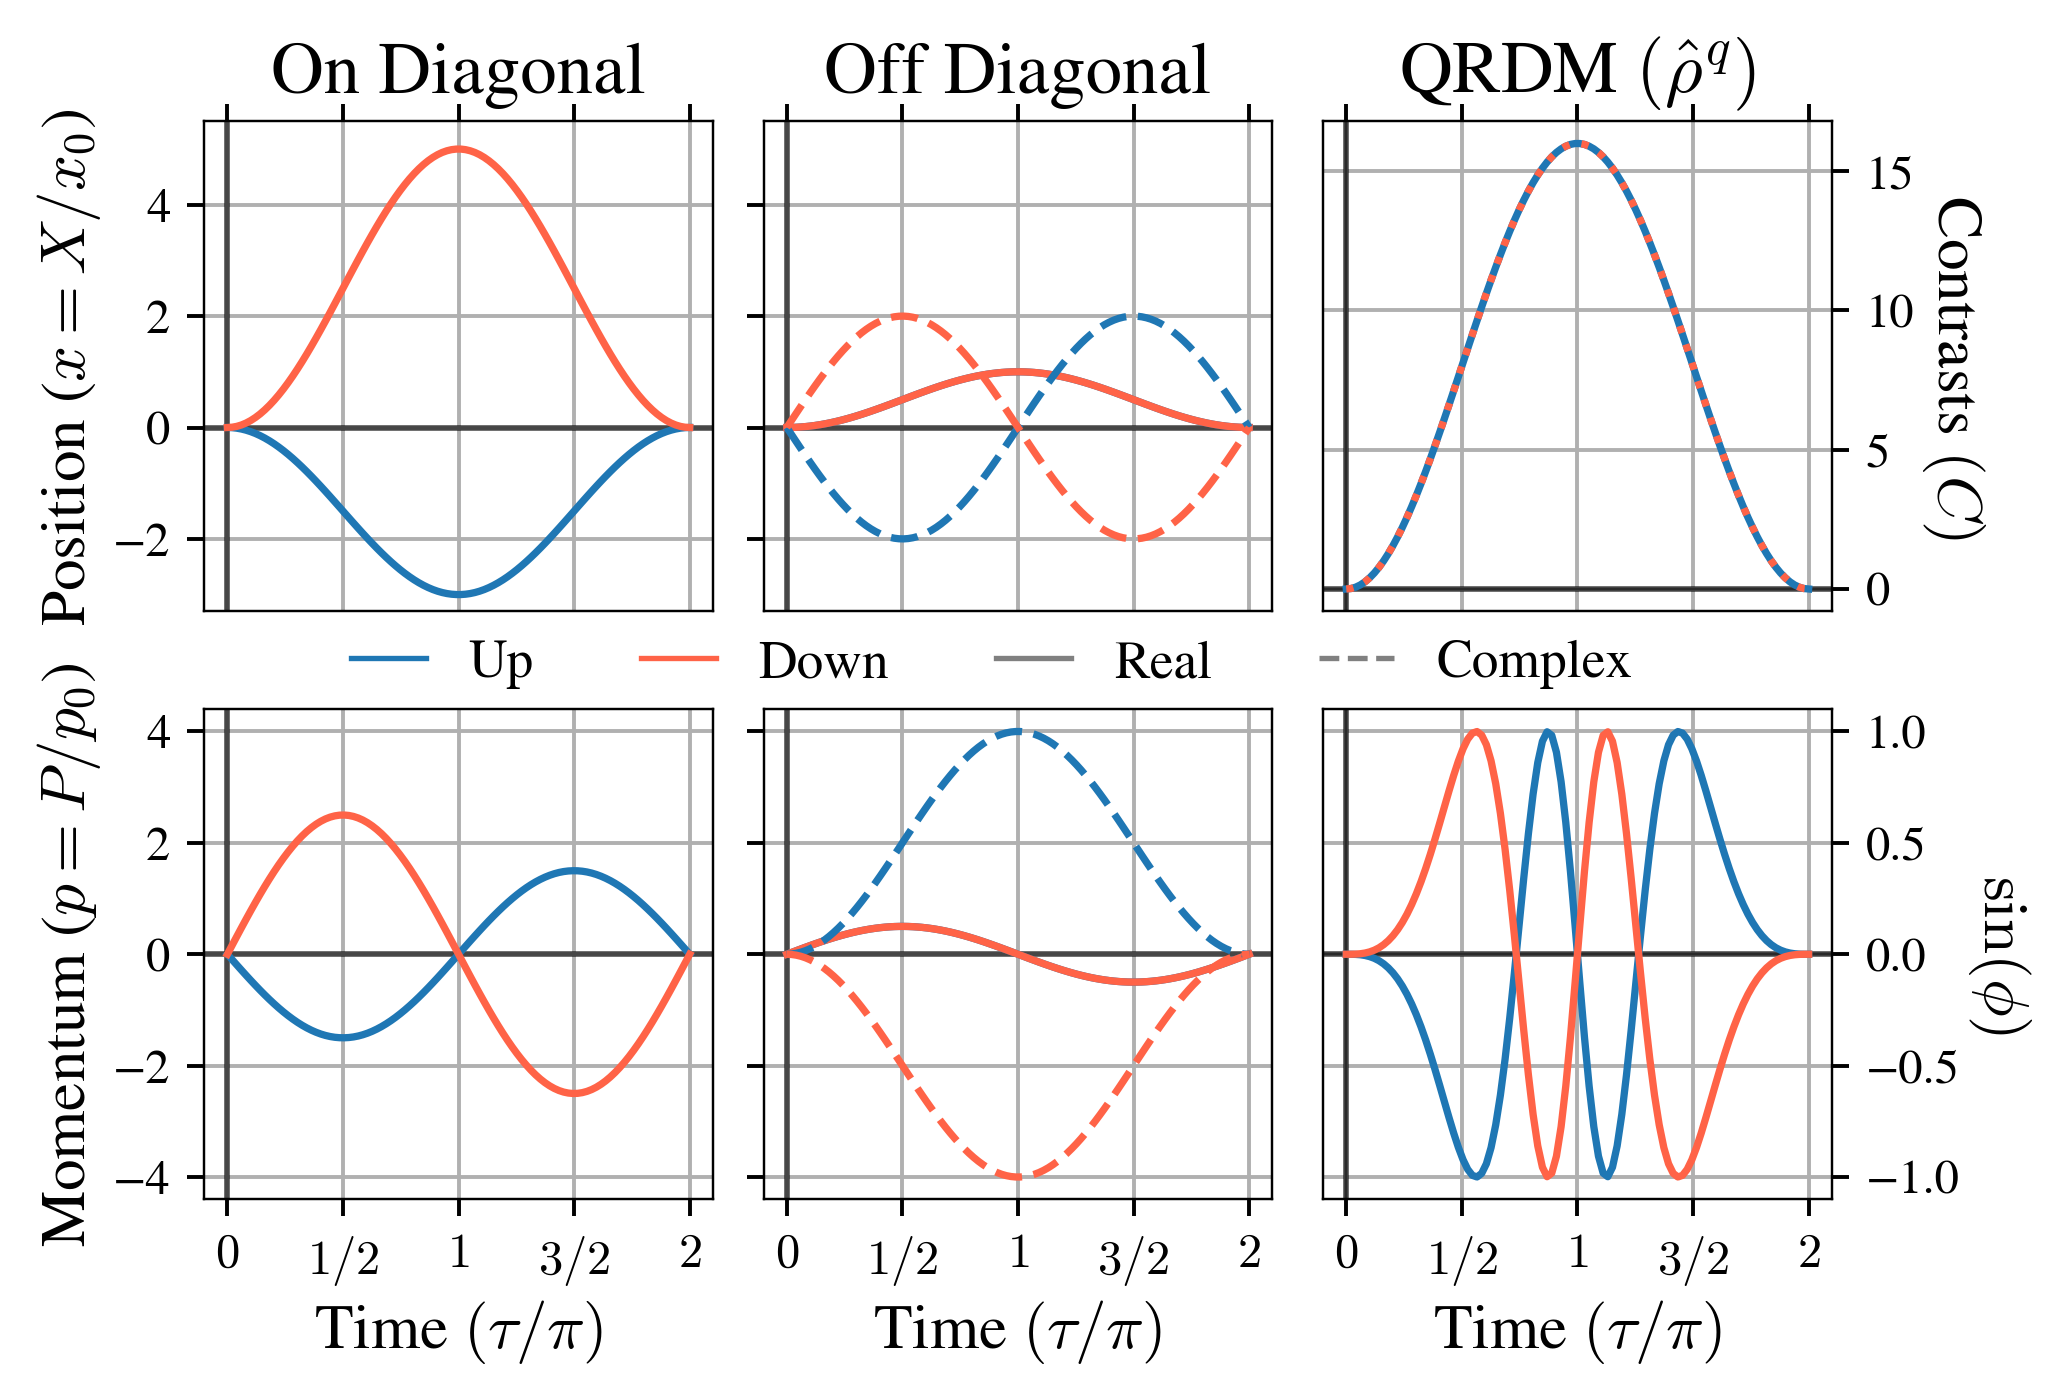

In [5]:
N_qubits = 1
n_modes = 1

omega = 1

########################## Hamiltonians ##########################

H_1_force = Hamiltonian(N_qubits, n_modes)

H_null = np.zeros((2*n_modes,2*n_modes)) 
iden = np.eye(2*n_modes)
r_null = np.zeros((2*n_modes,1)) 

H_m = omega*np.eye(2)
r_m =  np.array([[0.5],[0.0]])
H_q = H_null
r_q = np.array([[2.0],[0.0]])

H_q_0_array = np.array([0 +0*1j])
H_1_force.Initialize_Constant_Hamiltonians([H_m], [r_m, r_q], H_q_0_array)

########################## Initialize State ##########################

r_0 = np.array([[0.0],
                [0.0]])
sigma_0 = iden
rho_q_0 = np.ones((2*N_qubits,2*N_qubits))/(2**(2*N_qubits))


GCS = Quantum_State(N_qubits, n_modes)
GCS.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)

########################## Initialize Sympeltic Methods ##########################

Symp_QHO_1 = Symplectic(N_qubits, n_modes)

symplectic_name = "QHO_1"
symplectic_parameters = omega

Symp_QHO_1.Initialize_Constant_Symplectic(symplectic_name, symplectic_parameters)

t_array = np.linspace(0,2*np.pi, 100)


GCS.Unitary_Dynamics_Analytical(H_1_force, Symp_QHO_1, t_array)

########################## Plot First Moments ##########################

Parameter_list = []
array_pi = np.linspace(0,2,5)

GCS.Plot_Phase_Space_First_QRDM(Parameter_list, array_pi, False)

This is a time independent operator-valued force Hamiltonian
Initializing a Gaussian State


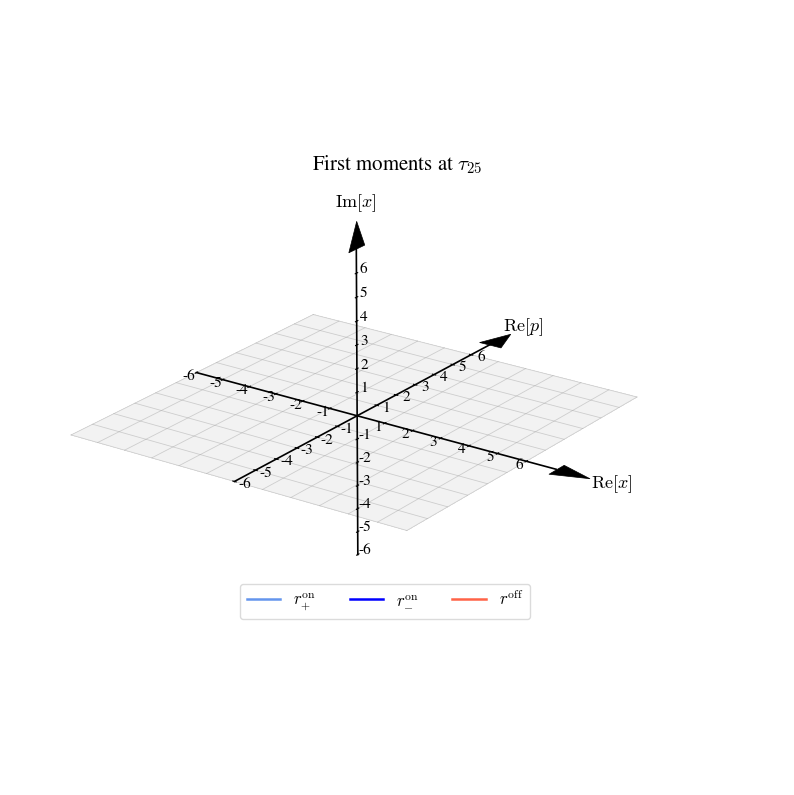

In [6]:

N_qubits = 1
n_modes = 1

omega = 1

########################## Hamiltonians ##########################

H_1_force = Hamiltonian(N_qubits, n_modes)

H_null = np.zeros((2*n_modes,2*n_modes)) 
iden = np.eye(2*n_modes)
r_null = np.zeros((2*n_modes,1)) 

H_m = omega*np.eye(2)
r_m =  np.array([[0.5],[0.0]])
H_q = H_null
r_q = np.array([[2.0],[0.0]])

H_q_0_array = np.array([0 +0*1j])
H_1_force.Initialize_Constant_Hamiltonians([H_m], [r_m, r_q], H_q_0_array)

########################## Initialize State ##########################

r_0 = np.array([[0.0],
                [0.0]])
sigma_0 = iden
rho_q_0 = np.ones((2*N_qubits,2*N_qubits))/(2**(2*N_qubits))


GCS = Quantum_State(N_qubits, n_modes)
GCS.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)

########################## Initialize Sympeltic Methods ##########################

Symp_QHO_1 = Symplectic(N_qubits, n_modes)

symplectic_name = "QHO_1"
symplectic_parameters = omega

Symp_QHO_1.Initialize_Constant_Symplectic(symplectic_name, symplectic_parameters)

t_array = np.linspace(0,2*np.pi, 100)


GCS.Unitary_Dynamics_Analytical(H_1_force, Symp_QHO_1, t_array)

########################## Plot First Moments ##########################

Parameter_list = []
array_pi = np.linspace(0,2,4)

t_idx = 0
GCS.Plot_Vectors_Single(
    t_idx=t_idx,
    z_comp=0,
    save="3d_plot_base.svg",
    title=r"First moments at $\tau_{25}$"
)
plt.show()

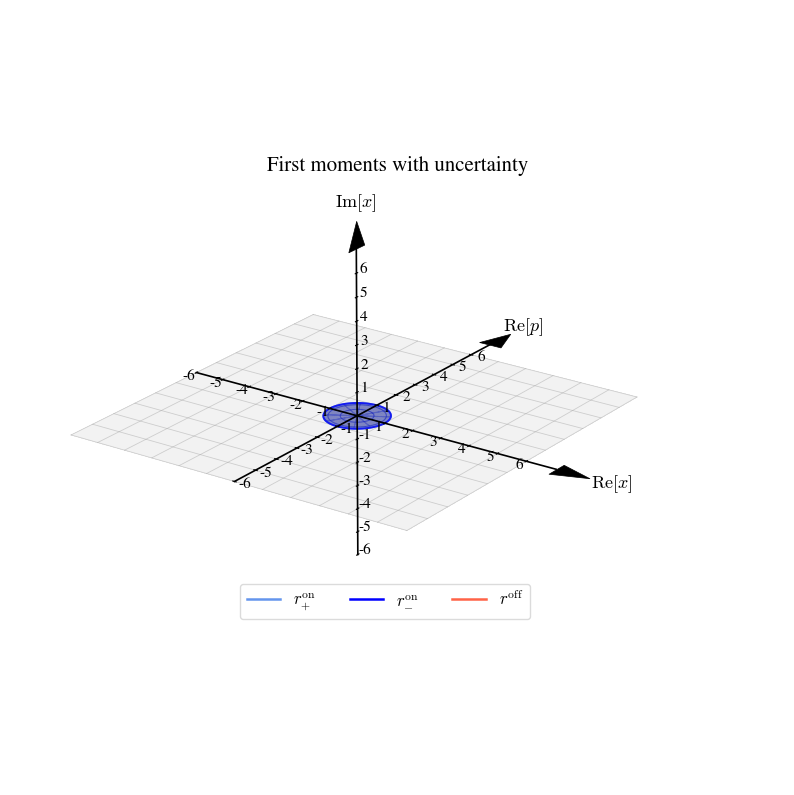

In [7]:
ani = GCS.Animate_Vectors_Ellipsoids_Single(
    z_comp=0,
    title=r"First moments with uncertainty",
    n_frames=len(GCS.t_array),
    interval=60,
    save="ellipsoids_SG.gif",
)
plt.show()

## Quadratic Mode-Qubits Interaction: 
## An Atom and a Cavity Interacting via Dissipative Coupling

### Numerical

In [8]:
N_qubits = 1
n_modes = 1

########################## Hamiltonians ##########################

H_1_general = Hamiltonian(N_qubits, n_modes)

H_null = np.zeros((2*n_modes,2*n_modes)) 
iden = np.eye(2*n_modes)
r_null = np.zeros((2*n_modes,1)) 

H_m = H_null
r_m = r_null
H_q = np.eye(2)
r_q = r_null

H_q_0_array = np.array([0 +0*1j])

H_1_general.Initialize_Constant_Hamiltonians([H_m, H_q], [r_m, r_q], H_q_0_array)

########################## Initialize State ##########################

s= 1/2
Np = 0

r_0 = np.array([[3.0],
                [0.0]])

sigma_0 = (1+2*Np)*np.array([[1.0/s, 0],
                [0.0, s]])
rho_q_0 = np.ones((2*N_qubits,2*N_qubits))/(2**(2*N_qubits))

GCS = Quantum_State(N_qubits, n_modes)
GCS.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)


########################## Dynamics ##########################
t_seps = 200
t_array = np.linspace(0,2*np.pi, t_seps)

GCS.Unitary_Dynamics_Numerical(H_1_general, t_array)


########################## Plot First Moments ##########################


#gaussian_state_general.Plot_Phase_Space_First_QRDM(Parameter_list, array_pi, False);

This is a time independent operator-valued general Hamiltonian
Initializing a Gaussian State


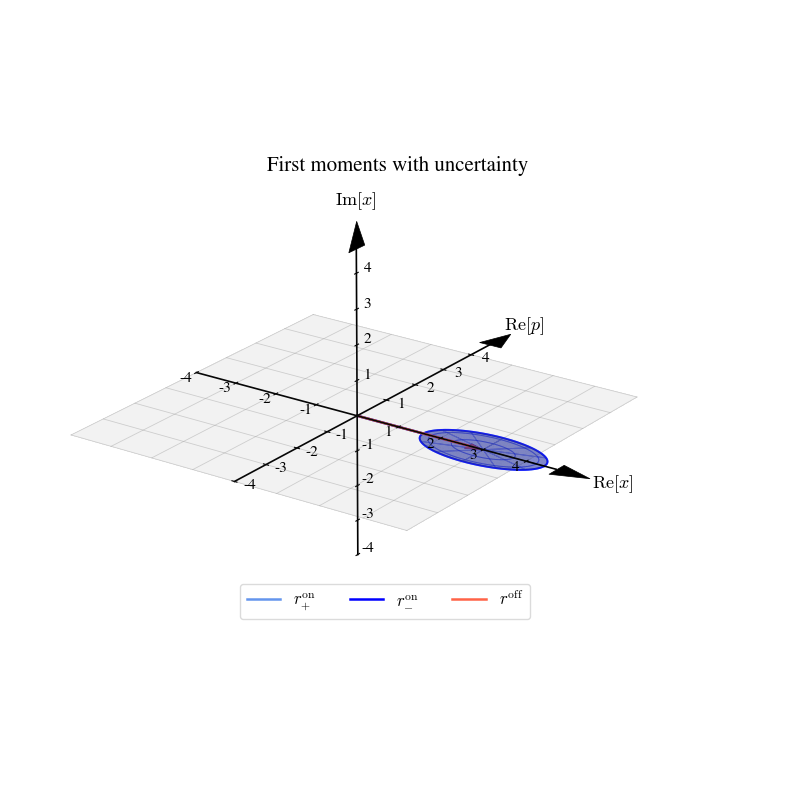

In [9]:
ani = GCS.Animate_Vectors_Ellipsoids_Single(
    z_comp=0,
    title=r"First moments with uncertainty",
    n_frames=len(GCS.t_array),
    interval=40,
    save="ellipsoids_Disp.gif",
)
plt.show()

/opt/anaconda3/lib/python3.11/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: divide by zero encountered in det
  r = _umath_linalg.det(a, signature=signature)
/opt/anaconda3/lib/python3.11/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)
/opt/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/opt/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


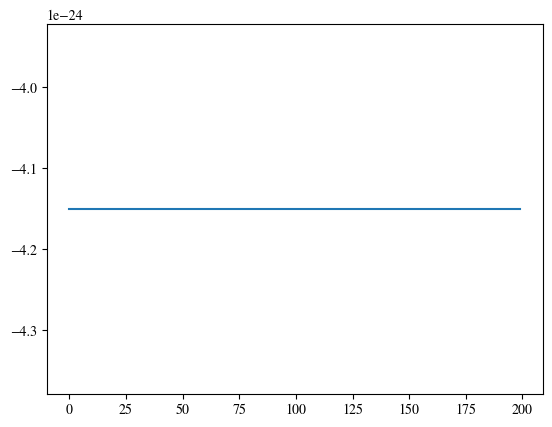

In [10]:
det_array = np.zeros((3,t_seps), dtype=complex)

for i in range(t_seps):
    det_array[0] =  np.linalg.det(GCS.sigma_JK_t[i,0,1])
    det_array[1] =  np.linalg.det(np.real(GCS.sigma_JK_t[i,0,1]))
    det_array[2] =  np.linalg.det(np.imag(GCS.sigma_JK_t[i,0,1]))



plt.plot(det_array[2])

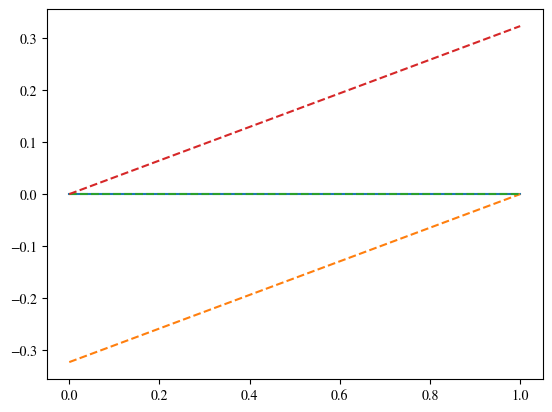

In [11]:
plt.plot(GCS.phi_JK_t[0,0])
plt.plot(GCS.phi_JK_t[1,1],'--')
plt.plot(GCS.phi_JK_t[0,1],'--')
plt.plot(GCS.phi_JK_t[1,0],'--')

## Time Dependent Mode-Qubits Interaction: 
## A Stern-Gerlach Intereferometer with Gaussian Unstable Dynamcis (Inverted Harmonic Oscillator) for Expansion of the Superposition 

### Numerical

This is a time dependent operator-valued general Hamiltonian
Initializing a Gaussian State


/opt/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/opt/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


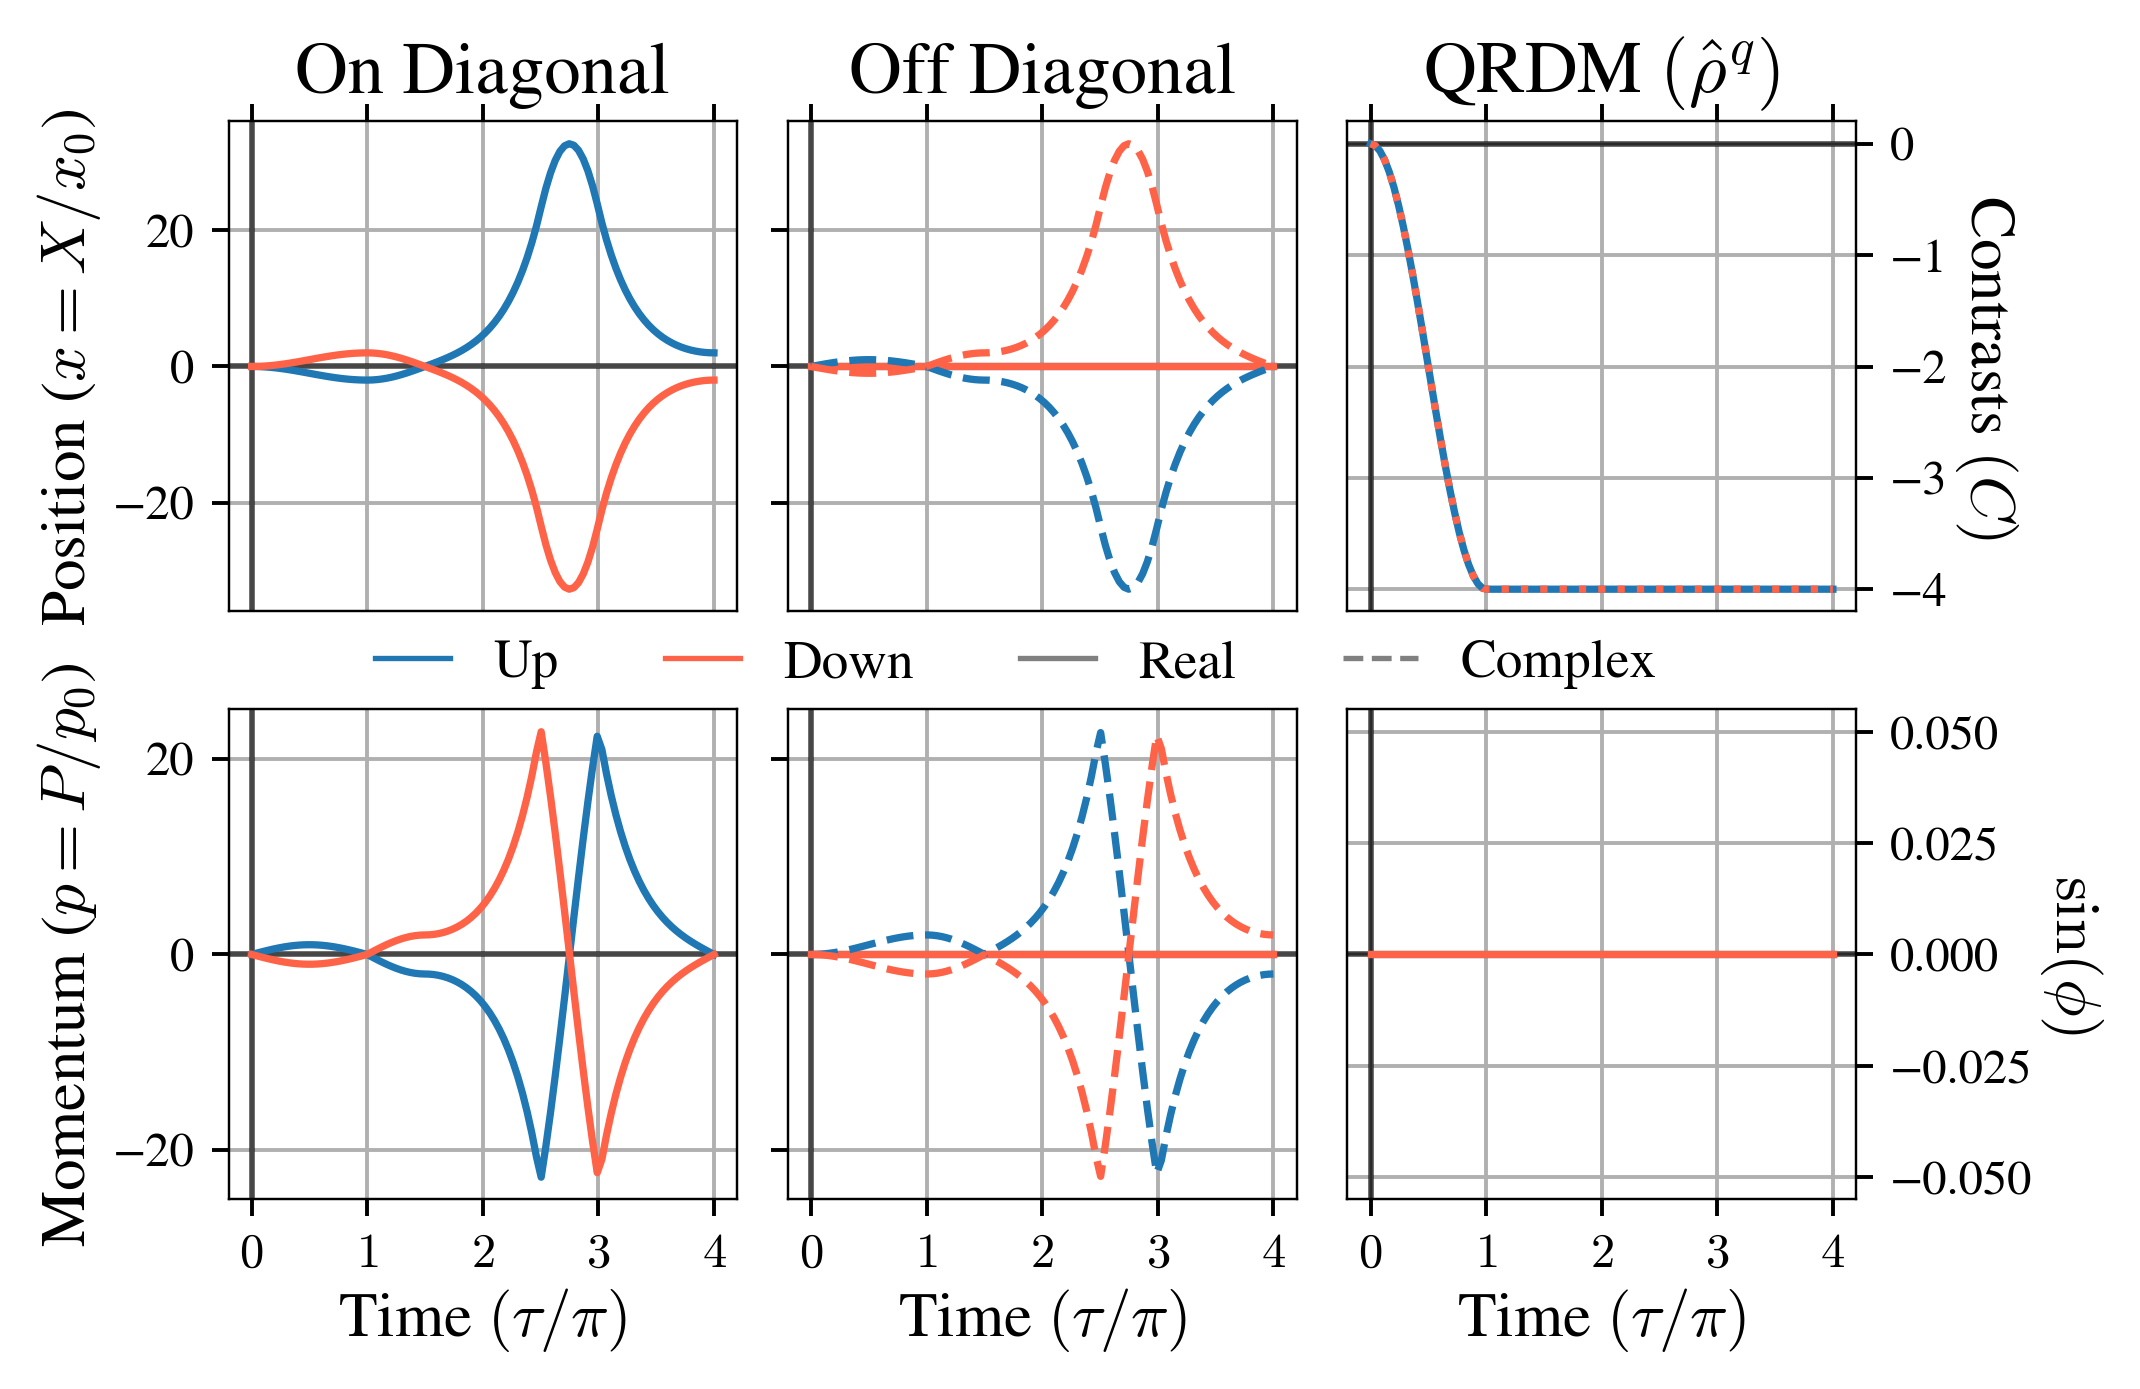

In [12]:
N_qubits = 1
n_modes = 1

########################## Hamiltonians ##########################

H_time_dep = Hamiltonian(N_qubits, n_modes)

t_plus = np.pi/2
t_minus =0.5* np.pi
t_split = np.pi

t_array = np.linspace(0, 2*(t_split + t_plus + t_minus),100)

def H_m_t(t):

    iden = np.eye(2*n_modes)

    t_plus = np.pi/2
    t_minus = np.pi
    t_split = np.pi

    H_QHO = iden
    H_IHO = np.array([[-1.0,0.0],[0.0,1.0]])

    if t < t_split:
        H_mat = H_QHO
    elif t >= t_split and t < t_split + t_plus:
        H_mat = H_QHO
    elif t >= t_split + t_plus and t < t_split + t_plus + t_minus:
        H_mat = H_IHO
    elif t >= t_split + t_plus + t_minus and t < t_split + 2*t_plus + t_minus:
        H_mat = H_QHO
    elif t >= t_split + 2*t_plus + t_minus and t < t_split + 2*t_plus + 2*t_minus:
        H_mat = H_IHO
    else:
        H_mat = np.zeros((2,2))
    
    return H_mat

def r_q_t(t):

    iden = np.eye(2*n_modes)
    r_null = np.zeros((2*n_modes,1)) 

    t_plus = np.pi/2
    t_minus = np.pi
    t_split = np.pi

    f_q = 1

    if t < t_split:
        r_mat = f_q* np.array([[1],[0]])
    elif t > t_split + 2*t_plus + 2*t_minus:
        r_mat = -f_q* np.array([[1],[0]])
    else: 
        r_mat = r_null
    return r_mat


def H_q_t(t):
    return  np.zeros((2*n_modes,2*n_modes))  

def r_m_t(t):
    return np.zeros((2*n_modes,1)) 

def H_q_0_t(t):
    return 0


H_array_func = [H_m_t, H_q_t]
r_array_func = [r_m_t, r_q_t]
H_q_0_array_func = [H_q_0_t]

H_time_dep.Initialize_Time_Dep_Hamiltonian(H_array_func, r_array_func, H_q_0_array_func, t_array)

########################## Initialize State ##########################

r_0 = np.array([[0.0],
                [0.0]])
sigma_0 = iden
rho_q_0 = np.ones((2*N_qubits,2*N_qubits))/(2**(2*N_qubits))

GCS = Quantum_State(N_qubits, n_modes)
GCS.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)

########################## Dynamics ##########################

GCS.Unitary_Dynamics_Numerical(H_time_dep , t_array)


########################## Plot First Moments ##########################

array_pi = np.arange(0,4.1,1)
GCS.Plot_Phase_Space_First_QRDM(Parameter_list, array_pi, False);

Text(0.5, 1.0, 'down-up')

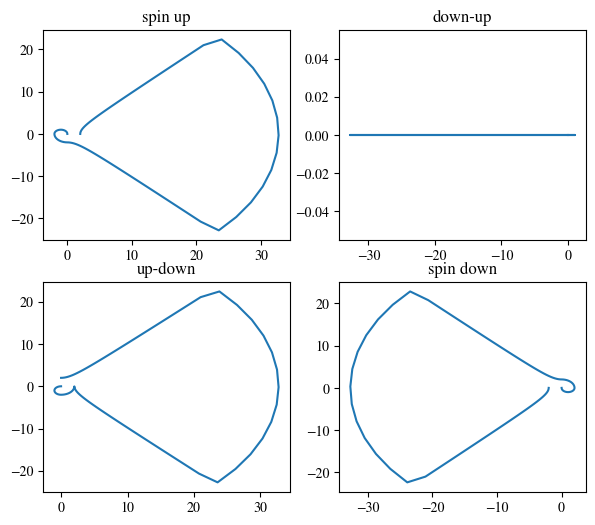

In [13]:
########################## Plot First Moments ##########################

fig, ax = plt.subplots(2, 2, figsize=(7,6))

ax[0,0].plot(GCS.r_JK_t[:,0,0,0],GCS.r_JK_t[:,0,0,1])
ax[0,0].set_title('spin up')

ax[1,0].plot(np.imag(GCS.r_JK_t[:,1,0,0]), np.imag(GCS.r_JK_t[:,1,0,1]))
ax[1,0].set_title('up-down')

ax[1,1].plot(GCS.r_JK_t[:,1,1,0],GCS.r_JK_t[:,1,1,1])
ax[1,1].set_title('spin down')

ax[0,1].plot(np.imag(GCS.r_JK_t[:,0,1,0]),np.imag(GCS.r_JK_t[:,0,0,1]))
ax[0,1].set_title('down-up')

## 3D Phase-Space Plots

The three functions below visualise the complex first-moment vectors `r_JK_t` (and optionally `sigma_JK_t`) in a 3-D phase space whose axes are Re[x], Re[p], and Im[x] (or Im[p] when `z_comp=1`).

The four curves/vectors correspond to the four (J,K) index pairs tracked by the library:
- **`r^on_+`** — diagonal entry (0,0), blue
- **`r^on_-`** — diagonal entry (1,1), darker blue
- **`r^off`** — off-diagonal entry (0,1), red
- **`(r^off)*`** — off-diagonal entry (1,0), darker red

> **Prerequisites**: run the *"Gaussian Unitary Dynamics — Numerical"* cell (cell 7) first so that the `GCS` object is in scope.

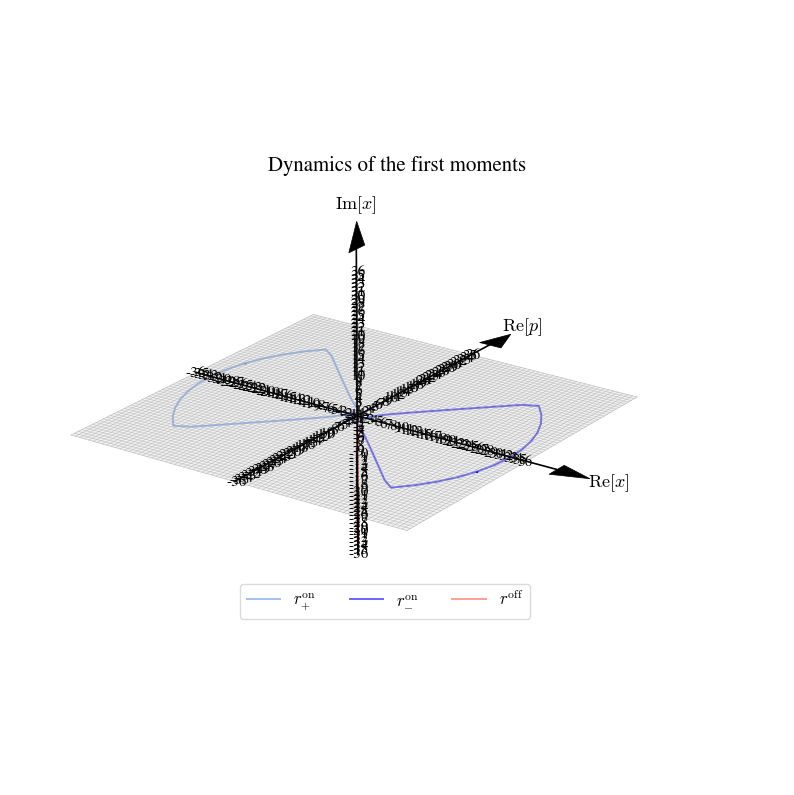

In [14]:
# ── Plot_Trajectories_Single ─────────────────────────────────────────────────
# Plots the full time-evolution of r_JK as 3-D curves.
# z_comp=0 → z-axis = Im[x];  z_comp=1 → z-axis = Im[p]

# Default call – auto title and auto legend
GCS.Plot_Trajectories_Single(z_comp=0)
plt.show()

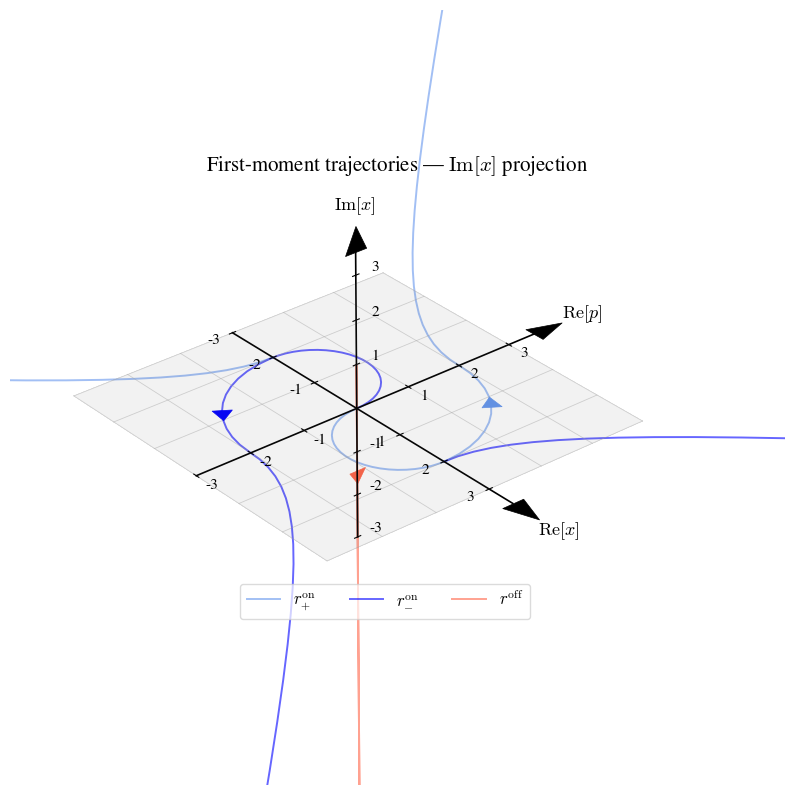

In [15]:
# ── Plot_Trajectories_Single — custom view ────────────────────────────────────
# Custom title, explicit axis limits, and rotated camera

GCS.Plot_Trajectories_Single(
    z_comp=0,
    title=r"First-moment trajectories — $\mathrm{Im}[x]$ projection",
    sym_lim=(-3, 3),   # fix all three axes to [-3, 3]
    elev=30, azim=-40,
)
plt.show()

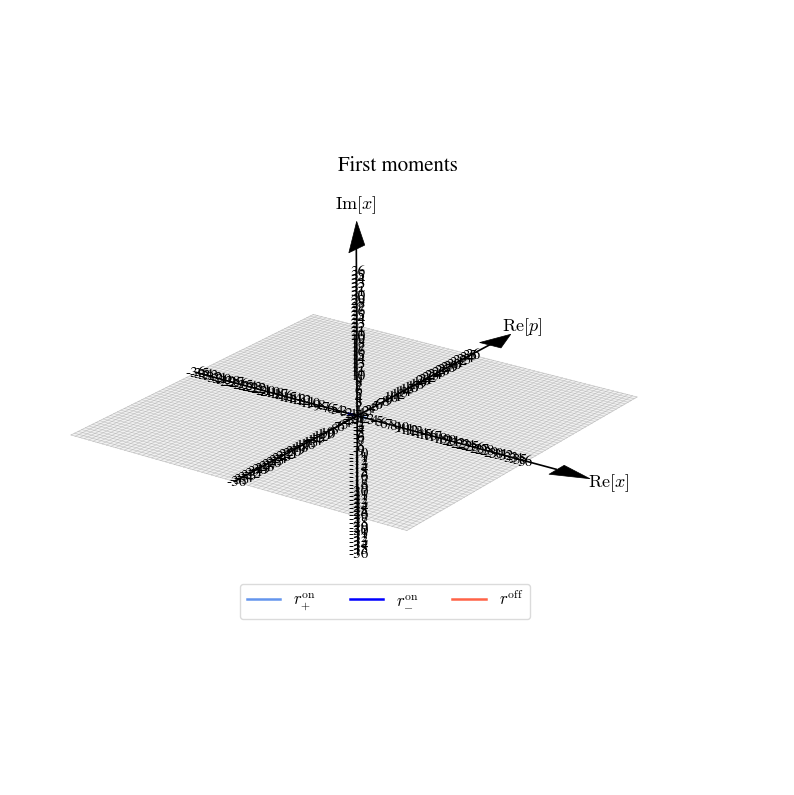

In [16]:
# ── Plot_Vectors_Single ───────────────────────────────────────────────────────
# Plots r_JK as 3-D arrows (vectors) at a chosen time snapshot.
# t_idx selects the time index along GCS.t_array.

t_idx = 25   # snapshot at t_array[25]

# Default call
GCS.Plot_Vectors_Single(t_idx=t_idx, z_comp=0)
plt.show()

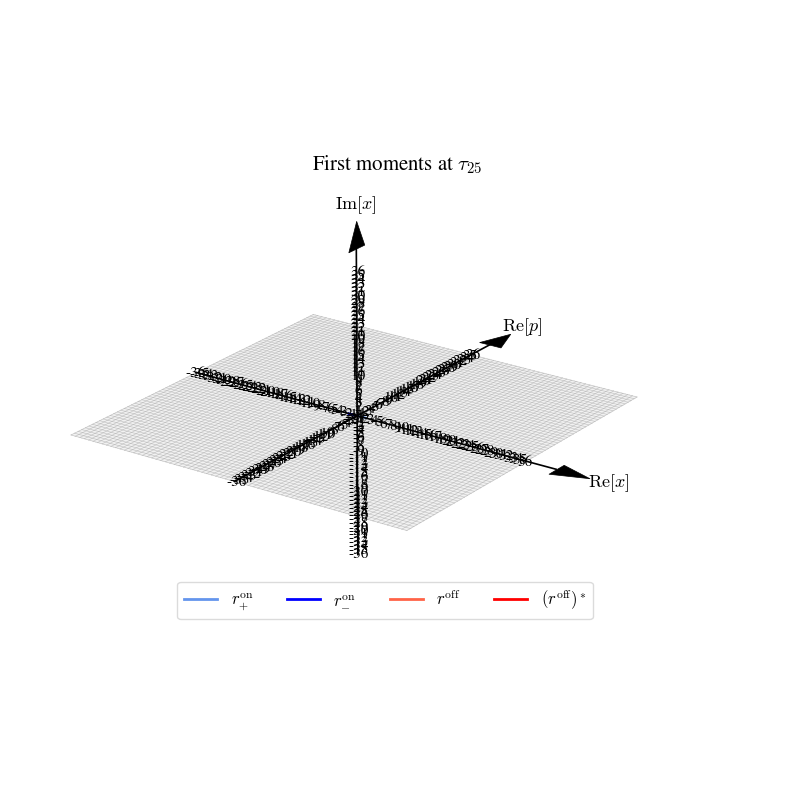

In [17]:
# ── Plot_Vectors_Single — custom legend ───────────────────────────────────────
# Build custom legend handles with Plots_Functions helpers, then pass them in.

import Plots_Functions as Plots_Functions

handles = [
    Plots_Functions.Make_Legend_Handle_3D(r"$r^{\mathrm{on}}_{+}$",  color='cornflowerblue'),
    Plots_Functions.Make_Legend_Handle_3D(r"$r^{\mathrm{on}}_{-}$",  color='blue'),
    Plots_Functions.Make_Legend_Handle_3D(r"$r^{\mathrm{off}}$",      color='tomato'),
    Plots_Functions.Make_Legend_Handle_3D(r"$(r^{\mathrm{off}})^*$", color='red'),
]

GCS.Plot_Vectors_Single(
    t_idx=t_idx,
    z_comp=0,
    title=r"First moments at $\tau_{25}$",
    legend_handles=handles,
)
plt.show()

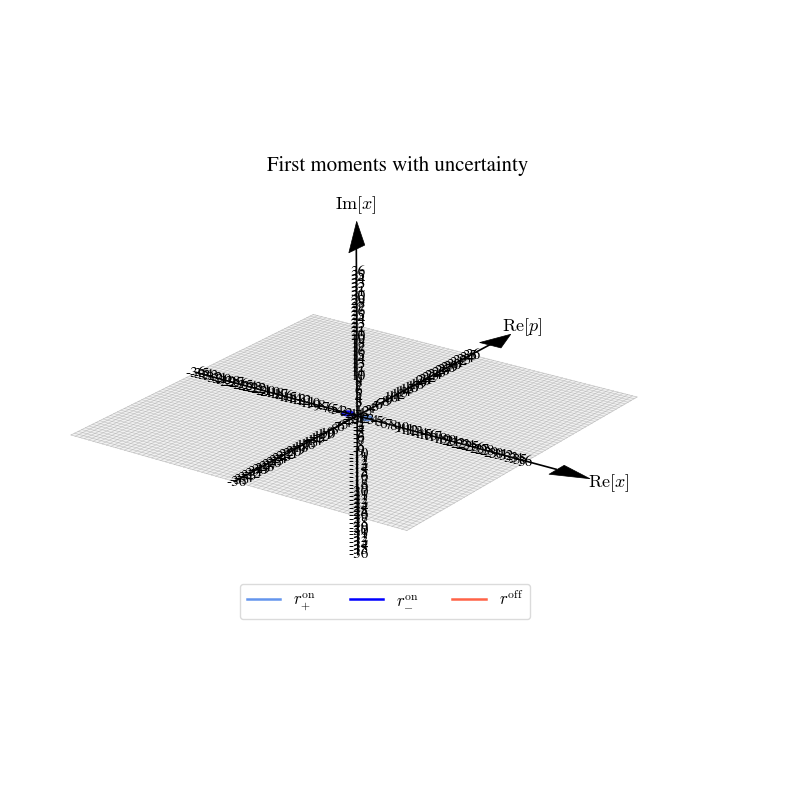

In [18]:
# ── Plot_Vectors_Ellipsoids_Single ────────────────────────────────────────────
# Extends Plot_Vectors_Single by drawing an uncertainty ellipsoid around each
# vector tip.  Semi-axes = sqrt of the diagonal entries of sigma_JK.

# Default call
GCS.Plot_Vectors_Ellipsoids_Single(t_idx=t_idx, z_comp=0)
plt.show()

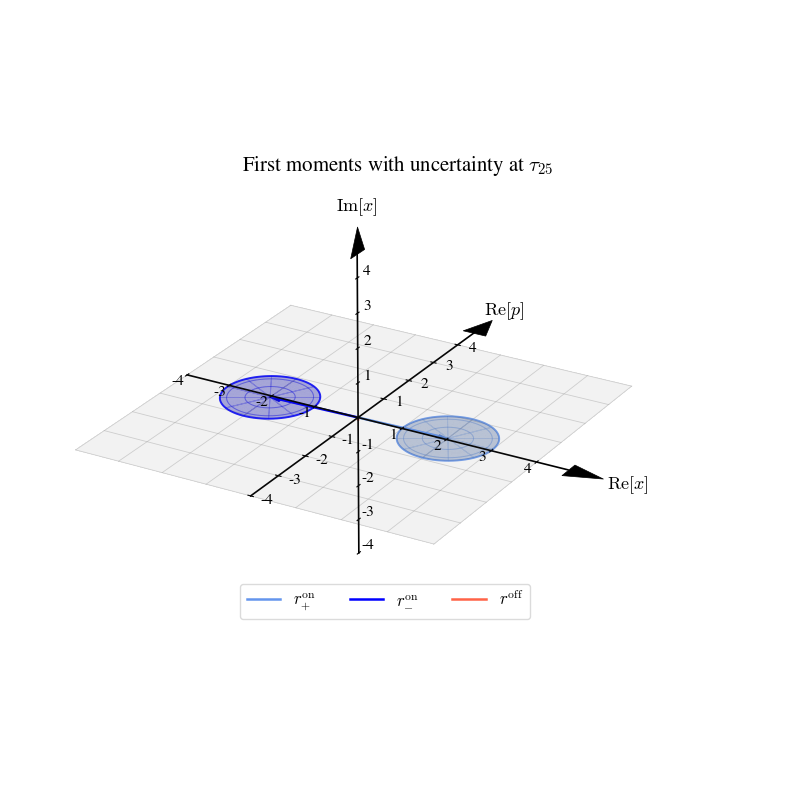

In [19]:
# ── Plot_Vectors_Ellipsoids_Single — custom title and view ───────────────────

GCS.Plot_Vectors_Ellipsoids_Single(
    t_idx=t_idx,
    z_comp=0,
    title=r"First moments with uncertainty at $\tau_{25}$",
    sym_lim=(-4, 4),
    elev=25, azim=-60,
)
plt.show()

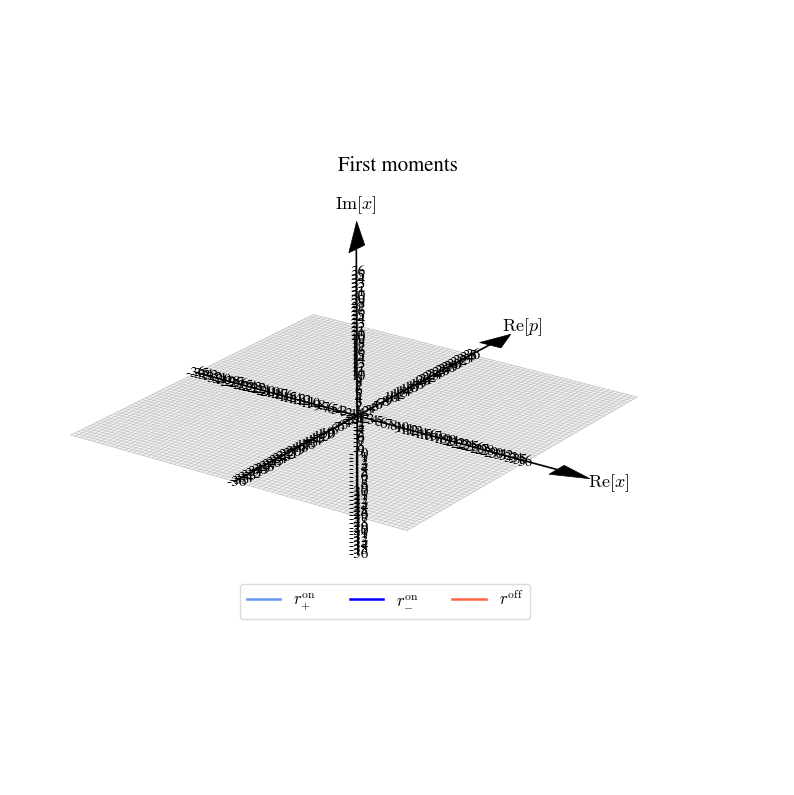

In [20]:
# ── Animate_Vectors_Single ───────────────────────────────────────────────────
# Animates the snapshot-vector plot over all time steps.
# Returns a FuncAnimation object; pass save="anim.gif" to write to disk.

ani = GCS.Animate_Vectors_Single(z_comp=0, interval=50)
plt.show()

/opt/anaconda3/lib/python3.11/site-packages/matplotlib/animation.py:892: UserWarning: Animation was deleted without rendering anything. This is most likely not intended. To prevent deletion, assign the Animation to a variable, e.g. `anim`, that exists until you output the Animation using `plt.show()` or `anim.save()`.
  warnings.warn(


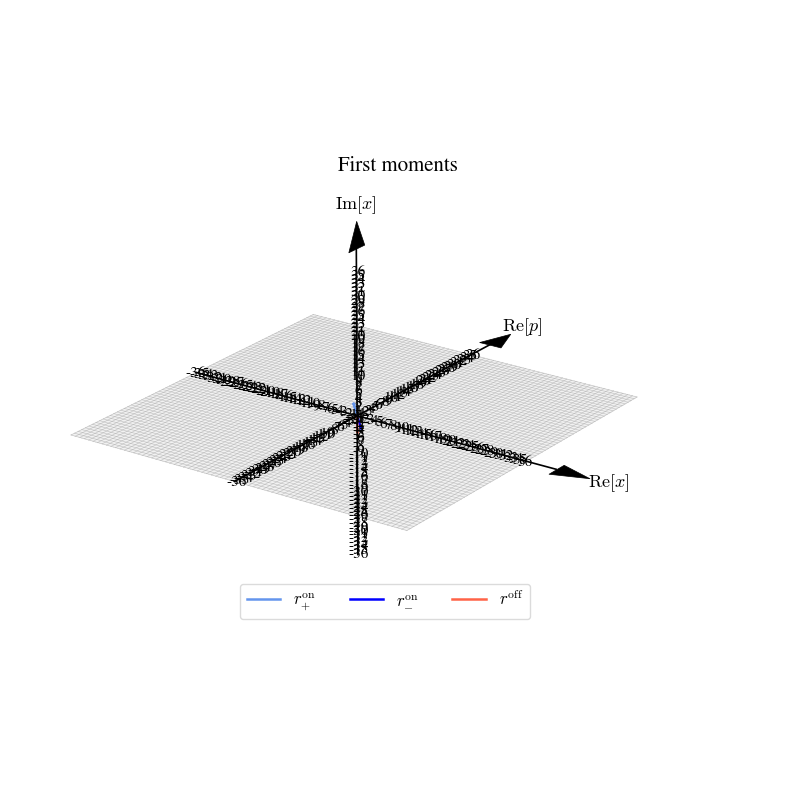

In [21]:
# ── Animate_Vectors_Single — save to file ────────────────────────────────────

ani = GCS.Animate_Vectors_Single(
    z_comp=0,
    title="First moments",
    n_frames=50,        # animate only the first 50 time steps
    interval=60,
    save="vectors_anim.gif",
)
plt.show()

In [22]:
# ── Animate_Vectors_Ellipsoids_Single ────────────────────────────────────────
# Same as above but each frame also draws the uncertainty ellipsoid.


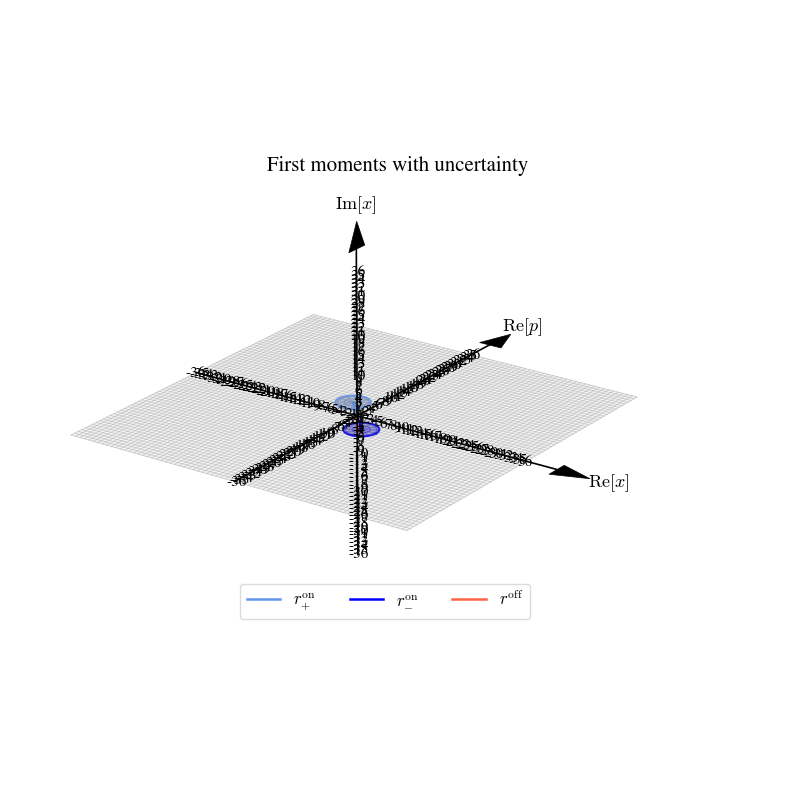

In [23]:
# ── Animate_Vectors_Ellipsoids_Single — save to file ─────────────────────────

ani = GCS.Animate_Vectors_Ellipsoids_Single(
    z_comp=0,
    title=r"First moments with uncertainty",
    n_frames=50,
    interval=60,
    save="vectors_ellipsoids_anim.gif",
)
plt.show()

## Quadratic Mode-Qubit Interaction: Displaced Thermal Squeezed State

Variant of the quadratic example above: $H_m = \mathbb{1}$, squeezing $s = 100$, thermal occupation $N_p = 100$, displacement $x_0 = 10$, $t \in [0, 2\pi]$ with 1000 steps. It uses its own state object `gaussian_state_general`, so the examples above are unaffected.

(An earlier version of the *Analytical (with Unknown Force)* example used $r_q = (1, 0)^T$ instead of $(2, 0)^T$.)

In [24]:
N_qubits = 1
n_modes = 1

########################## Hamiltonians ##########################

H_1_general = Hamiltonian(N_qubits, n_modes)

H_null = np.zeros((2*n_modes,2*n_modes)) 
iden = np.eye(2*n_modes)
r_null = np.zeros((2*n_modes,1)) 

H_m = np.eye(2)
r_m = r_null
H_q = np.eye(2)
r_q = r_null

H_q_0_array = np.array([0 +0*1j])

H_1_general.Initialize_Constant_Hamiltonians([H_m, H_q], [r_m, r_q], H_q_0_array)

########################## Initialize State ##########################

s= 100
Np = 100
r_0 = np.array([[10.0],
                [0.0]])

sigma_0 = (1+2*Np)*np.array([[1.0/s, 0],
                [0.0, s]])
rho_q_0 = np.ones((2*N_qubits,2*N_qubits))/(2**(2*N_qubits))

gaussian_state_general = Quantum_State(N_qubits, n_modes)
gaussian_state_general.Initialize_Gaussian_State(r_0, sigma_0, rho_q_0)


########################## Dynamics ##########################
t_seps = 1000
t_array = np.linspace(0,2*np.pi, t_seps)

gaussian_state_general.Unitary_Dynamics_Numerical(H_1_general, t_array)


########################## Plot First Moments ##########################


#gaussian_state_general.Plot_Phase_Space_First_QRDM(Parameter_list, array_pi, False);

This is a time independent operator-valued general Hamiltonian
Initializing a Gaussian State


/opt/anaconda3/lib/python3.11/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: divide by zero encountered in det
  r = _umath_linalg.det(a, signature=signature)
/opt/anaconda3/lib/python3.11/site-packages/numpy/linalg/linalg.py:2180: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)
/opt/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/opt/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


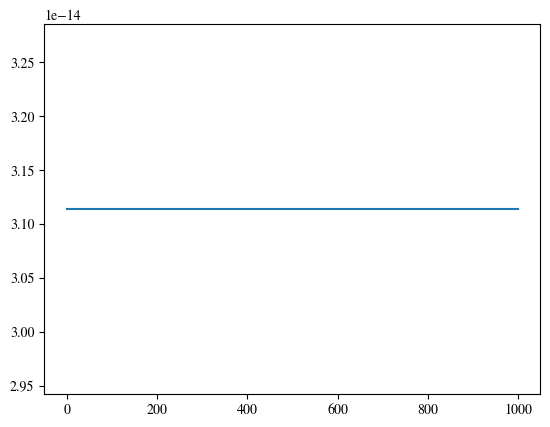

In [25]:
det_array = np.zeros((3,t_seps), dtype=complex)

for i in range(t_seps):
    det_array[0] =  np.linalg.det(gaussian_state_general.sigma_JK_t[i,0,1])
    det_array[1] =  np.linalg.det(np.real(gaussian_state_general.sigma_JK_t[i,0,1]))
    det_array[2] =  np.linalg.det(np.imag(gaussian_state_general.sigma_JK_t[i,0,1]))



plt.plot(det_array[2])

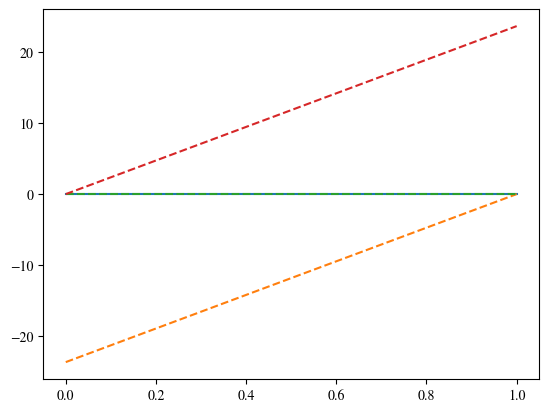

In [26]:
plt.plot(gaussian_state_general.phi_JK_t[0,0])
plt.plot(gaussian_state_general.phi_JK_t[1,1],'--')
plt.plot(gaussian_state_general.phi_JK_t[0,1],'--')
plt.plot(gaussian_state_general.phi_JK_t[1,0],'--')

Snapshots of the first moments and covariance ellipsoids of all branches, every 5 time steps:

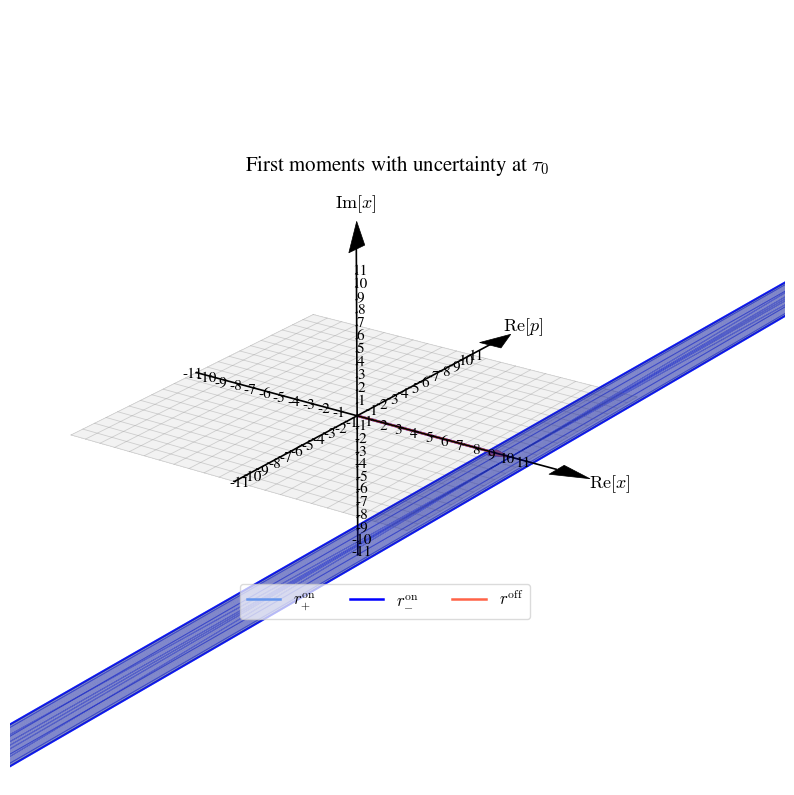

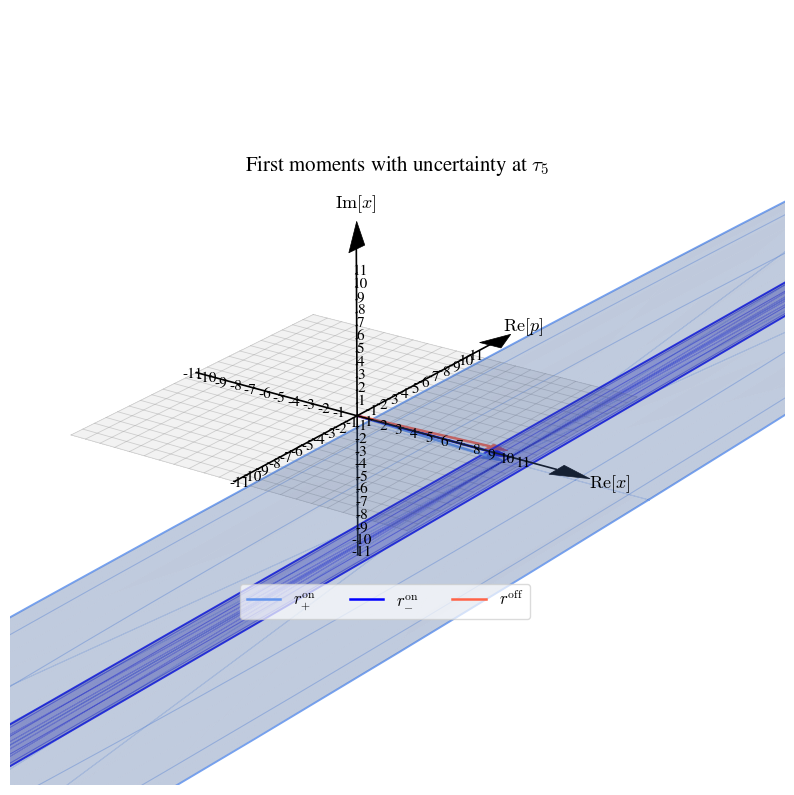

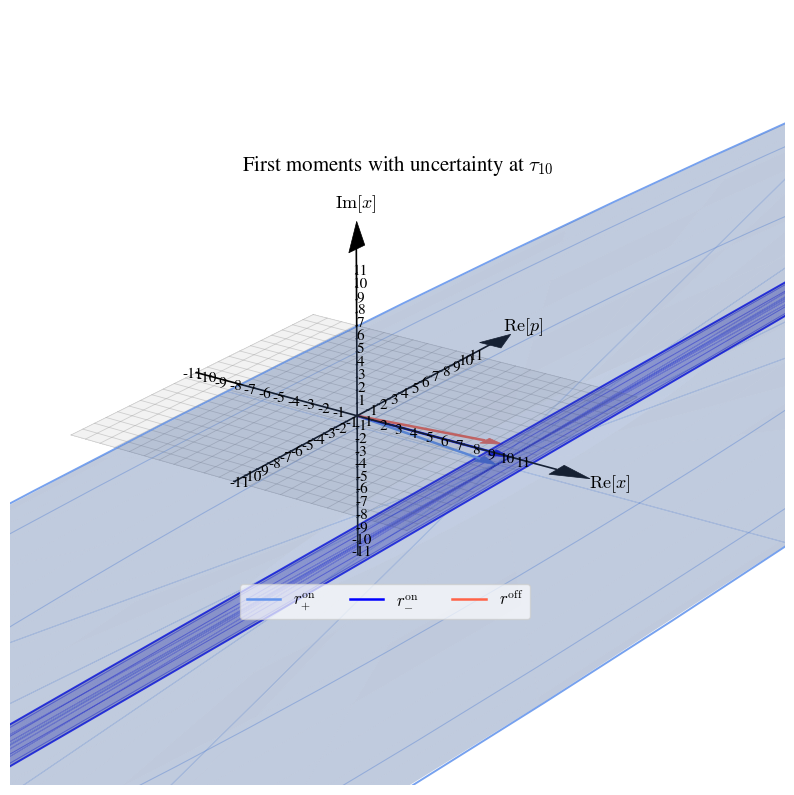

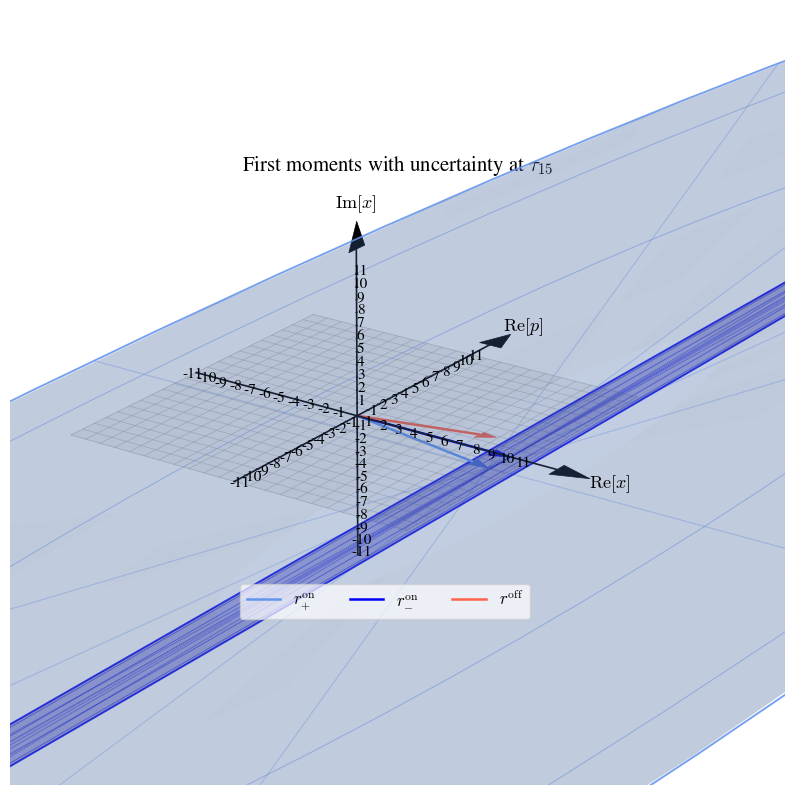

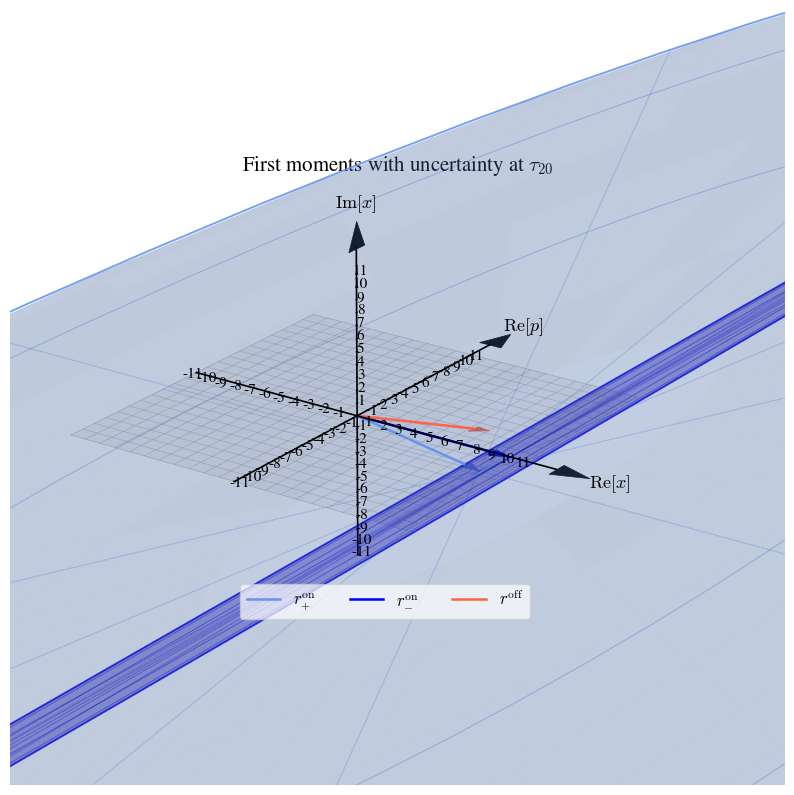

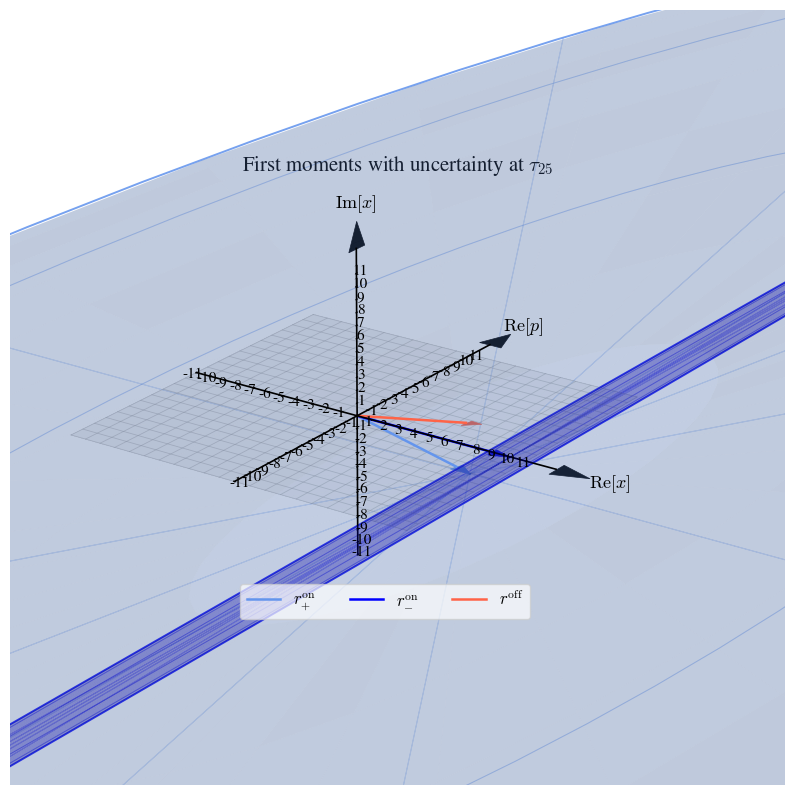

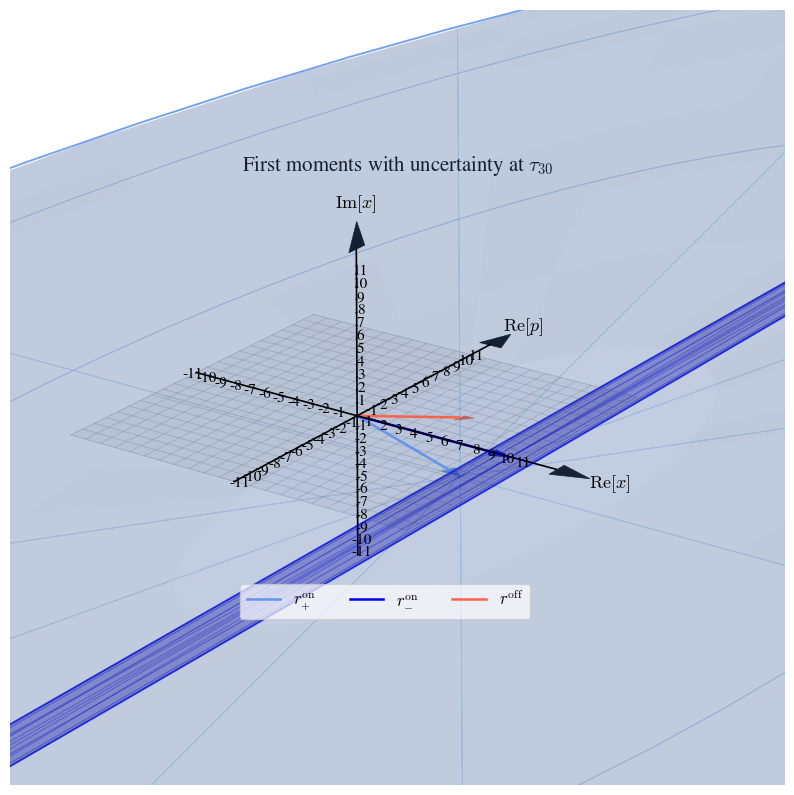

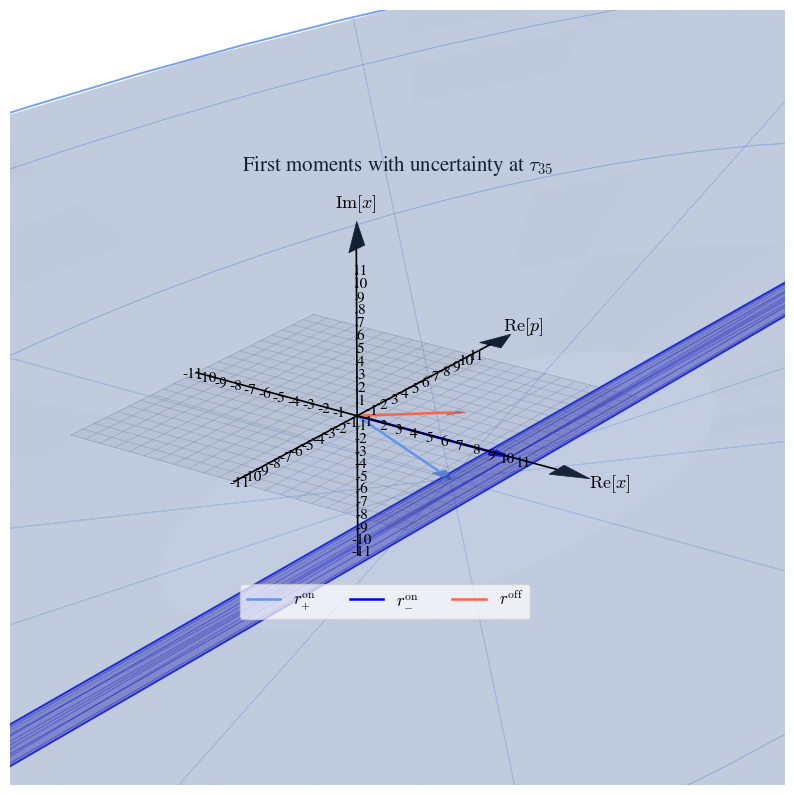

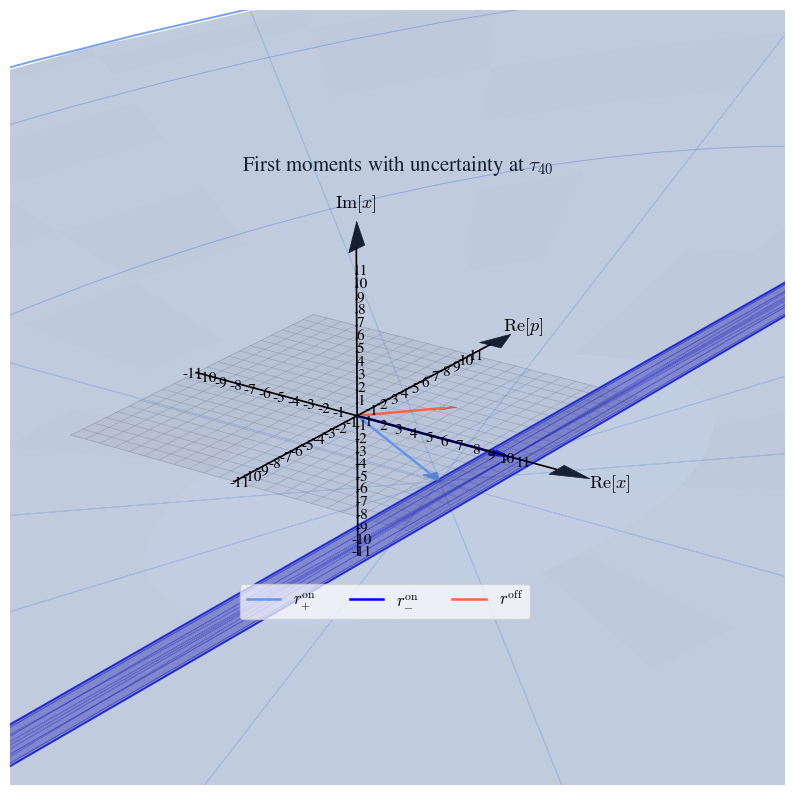

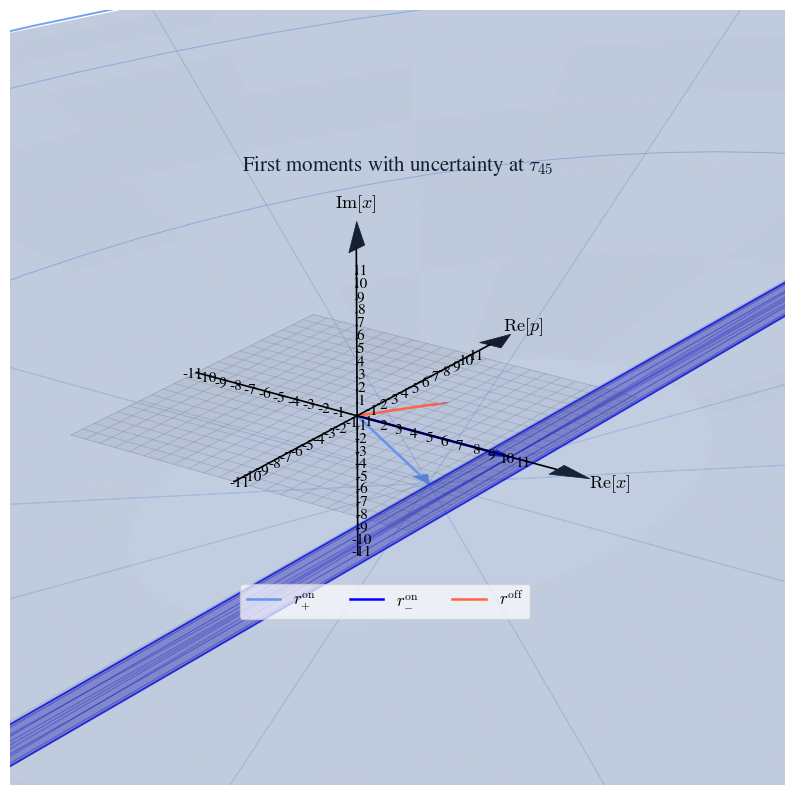

In [27]:
for i in range(10):
    gaussian_state_general.Plot_Vectors_Ellipsoids_Single(
        t_idx=i*5, z_comp=0,
        title=rf"First moments with uncertainty at $\tau_{{{i*5}}}$",
    )
    plt.show()

## Time-Dependent Gaussian Open Dynamics: Parametrically Driven QHO

H(t) = diag(1 + Δω sin(2t), 1) — parametric drive at twice the natural frequency (Mathieu equation).
Zero decoherence to verify the unitary limit.

This is a time dependent gaussian Hamiltonian
Initializing a Gaussian State


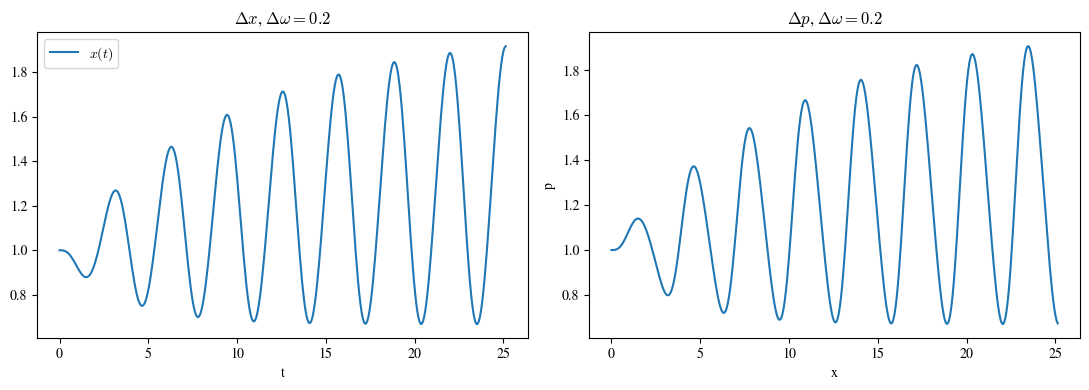

In [28]:
n_modes = 1
Delta_omega = 0.2
gamma_C = 0.2
phi_array = np.array( [0,0.1])
phi= 0

def H_m_driven(t):
    return np.array([[1 + Delta_omega * np.sin(2*t+phi), 0.0],
                     [0.0,                              1.0]])

def r_m_driven(t):
    return np.zeros((2*n_modes, 1))

t_array = np.linspace(0, 8*np.pi, 400)

H_driven = Hamiltonian(0, n_modes)
H_driven.Initialize_Time_Dep_Hamiltonian([H_m_driven], [r_m_driven], [], t_array)

s = 1
dx = 0
r_0     = np.array([[dx], [0.0]])
sigma_0 = np.array([[s,0],[0,1/s]])

gs = Quantum_State(0, n_modes)
gs.Initialize_Gaussian_State(r_0, sigma_0, np.ones((1, 1)))


B_a = gamma_C*np.array([[0.,1.],[0.,0.]])

Dec = Decoherence(0,n_modes,'Ladder', B_a)


gs.Open_Dynamics_Numerical(H_driven, Dec, t_array)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(t_array, np.real(gs.sigma_t[:, 0,0]), label=r'$x(t)$')
axes[0].set_xlabel('t')
axes[0].legend()
axes[0].set_title(fr'$\Delta x$, $\Delta\omega={Delta_omega}$')

axes[1].plot(t_array, np.real(gs.sigma_t[:, 1,1]), label=r'$p(t)$')
axes[1].set_xlabel('x')
axes[1].set_ylabel('p')
axes[1].set_title(fr'$\Delta p$, $\Delta\omega={Delta_omega}$')

plt.tight_layout()
plt.show()

/private/tmp/claude-501/-Users-lorenzobraccini-GitHub-GCS/a15ccb01-6e8a-4eac-8130-b30dcbffd6f6/scratchpad/run/src/Wigner_Functions.py:121: ComplexWarning: Casting complex values to real discards the imaginary part
  W_Gausss[m,n] += (2**n_modes)/(np.pi**n_modes * np.sqrt(det_sigma))*np.exp(-np.transpose(r_tilde_array[m,n] -r_first)@sigma_inv@(r_tilde_array[m,n] - r_first))[0,0]


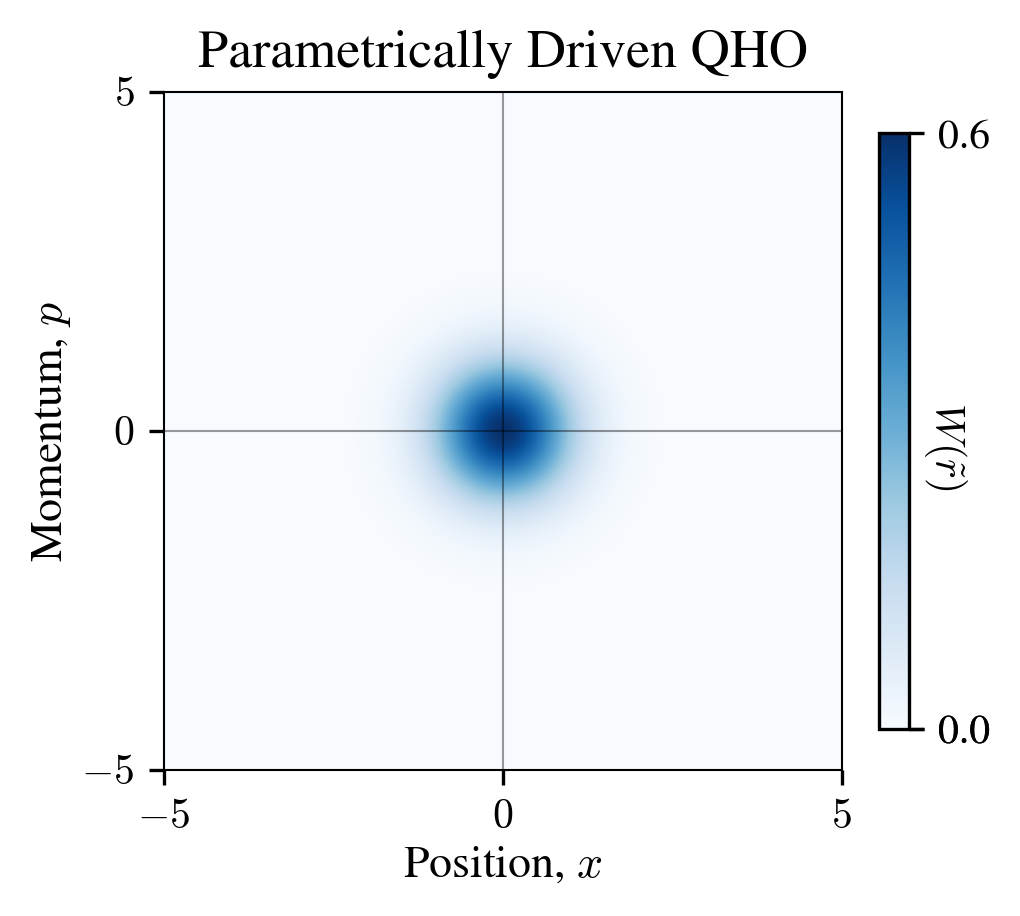

In [29]:
steps = 101
mode_number = 0
time_index = 40
bar_limits = [0,0.5]
sigma_para = 1.3
array_tick = np.linspace(-5,5,3)
n_frames = len(gs.t_array)

gs.Animate_Gaussian(steps, mode_number, sigma_para, array_tick, n_frames, "Parametrically Driven QHO" , 'driven_harmonic.gif')

## Centered Pancake (Off-diagonal Covariance) in 3-D Phase Space

For an off-diagonal GCS element the covariance matrix is

$$
\sigma^{\text{off}} =
\begin{pmatrix}
  e^{i\psi}|\zeta| & 0 \\\\
  0 & e^{-i\psi}/|\zeta|
\end{pmatrix}
$$

with

$$
\zeta^2 = \frac{\cos^2\theta_\Delta + s^2\sin^2\theta_\Delta}
               {\sin^2\theta_\Delta + s^2\cos^2\theta_\Delta}
$$

In the 3-D phase-space $(\mathrm{Re}[x],\,\mathrm{Re}[p],\,\mathrm{Im}[x])$
this is a **flat 2-D ellipse** (pancake) with centre at the origin ($r=0$)
and semi-axes $\sqrt{|\zeta|}$ and $1/\sqrt{|\zeta|}$, lying in the plane
spanned by

$$
\mathbf{u} = (\cos\psi,\,0,\,\sin\psi), \qquad
\mathbf{v} = (0,\,1,\,0)
$$

so the unit normal is $\hat{n} = (-\sin\psi,\,0,\,\cos\psi)$.
At $\psi=0$ the pancake lies flat in the $xy$-plane; increasing $\psi$ tilts it
toward the $\mathrm{Im}[x]$ axis.

In [30]:
import matplotlib.lines as mlines
from matplotlib.patches import Patch
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from Plots_Functions import (_make_scene_3d, _finalise_3d, _draw_vector_3d)


def zeta_from_params(theta_Delta, s):
    """
    |ζ| from branching angle θ_Δ and squeezing ratio s.
    ζ² = (cos²θ_Δ + s² sin²θ_Δ) / (sin²θ_Δ + s² cos²θ_Δ)
    """
    c2, s2 = np.cos(theta_Delta)**2, np.sin(theta_Delta)**2
    return np.sqrt((c2 + s**2 * s2) / (s2 + s**2 * c2))


def sigma_off_matrix(zeta_abs, psi):
    """σ^off = diag(e^{iψ}|ζ|, e^{-iψ}/|ζ|) as a 2×2 complex ndarray."""
    return np.diag([np.exp(1j * psi) * zeta_abs,
                    np.exp(-1j * psi) / zeta_abs])


def Plot_Pancake_3D(zeta_abs, psi,
                    sym_lim=2.0, figsize=(8, 8), elev=22, azim=-55,
                    color='tomato', alpha_fill=0.22, n_pts=300,
                    title=''):
    """
    Draw a centered 'pancake' (flat 2-D ellipse) in the GCS 3-D phase space
    (Re[x], Re[p], Im[x]).

    Off-diagonal covariance: σ^off = diag(e^{iψ}|ζ|, e^{-iψ}/|ζ|)

    Pancake plane spanned by:
        u = (cos ψ, 0, sin ψ)   semi-axis √|ζ|
        v = (0,     1,    0 )   semi-axis 1/√|ζ|
    Normal: n = u × v = (−sin ψ, 0, cos ψ)

    Overlays
    --------
    · filled face + solid edge  — the pancake
    · dotted ellipse            — projection onto Im[x] = 0
    · arrow                     — unit normal n̂

    Parameters
    ----------
    zeta_abs  : float > 0   |ζ|
    psi       : float (rad) tilt angle; ψ=0 → pancake lies flat in xy-plane
    sym_lim   : float       symmetric half-range for all three axes
    figsize   : (w, h)
    elev,azim : 3-D view angles (degrees)
    color     : face/edge colour of the pancake
    alpha_fill: face transparency (0–1)
    n_pts     : number of perimeter sample points
    title     : optional title string

    Returns
    -------
    fig, ax : Figure and Axes3D
    """
    theta = np.linspace(0, 2 * np.pi, n_pts)
    a = np.sqrt(zeta_abs)         # semi-axis along u
    b = 1.0 / np.sqrt(zeta_abs)  # semi-axis along v

    # Orthonormal basis of the pancake plane in (Re[x], Re[p], Im[x])
    u = np.array([ np.cos(psi), 0.0, np.sin(psi)])
    v = np.array([0.0,          1.0, 0.0        ])
    n = np.array([-np.sin(psi), 0.0, np.cos(psi)])  # u × v

    # Parametric 3-D ellipse, shape (n_pts, 3)
    P = np.outer(a * np.cos(theta), u) + np.outer(b * np.sin(theta), v)

    # Projection onto Im[x] = 0 plane
    P_proj      = P.copy()
    P_proj[:, 2] = 0.0

    # ── scene ──────────────────────────────────────────────────────────────
    fig, ax = _make_scene_3d((-sym_lim, sym_lim), z_comp=0,
                             figsize=figsize, elev=elev, azim=azim)

    # ── filled pancake face ────────────────────────────────────────────────
    verts = [list(zip(P[:, 0], P[:, 1], P[:, 2]))]
    ax.add_collection3d(
        Poly3DCollection(verts, facecolor=color, edgecolor='none',
                         alpha=alpha_fill, zorder=4))

    # Solid perimeter edge
    ax.plot(P[:, 0], P[:, 1], P[:, 2],
            color=color, linewidth=1.8, alpha=0.9, zorder=5)

    # ── xy-plane projection (dotted loop) ──────────────────────────────────
    ax.plot(P_proj[:, 0], P_proj[:, 1], P_proj[:, 2],
            linestyle=':', color='dimgray', linewidth=1.4, alpha=0.85, zorder=3)

    # Thin vertical drop-lines from pancake edge down to its xy projection
    step = max(1, n_pts // 32)
    for i in range(0, n_pts, step):
        ax.plot([P[i, 0], P_proj[i, 0]],
                [P[i, 1], P_proj[i, 1]],
                [P[i, 2], 0.0],
                color='gray', linewidth=0.4, alpha=0.35, linestyle='--')

    # ── unit normal arrow ──────────────────────────────────────────────────
    _draw_vector_3d(ax, n * 0.75 * sym_lim, color='black', lw=1.8)

    # ── legend + axis labels ───────────────────────────────────────────────
    handles = [
        Patch(facecolor=color, alpha=0.6,
              label=r'$\sigma^{\mathrm{off}}$ pancake'),
        mlines.Line2D([], [], color='dimgray', linestyle=':', linewidth=1.4,
                      label=r'$xy$-plane projection'),
        mlines.Line2D([], [], color='black', linewidth=1.8,
                      label=r'normal $\hat{n}$'),
    ]
    _finalise_3d(ax, fig, (-sym_lim, sym_lim), z_comp=0,
                 title=title, legend_handles=handles)

    return fig, ax


|ζ|  = 0.6547   (ζ² = 0.4286)
Semi-axes: √|ζ| = 0.8091,  1/√|ζ| = 1.2359
σ_off =
[[0.46291005+0.46291005j 0.        +0.j        ]
 [0.        +0.j         1.08012345-1.08012345j]]


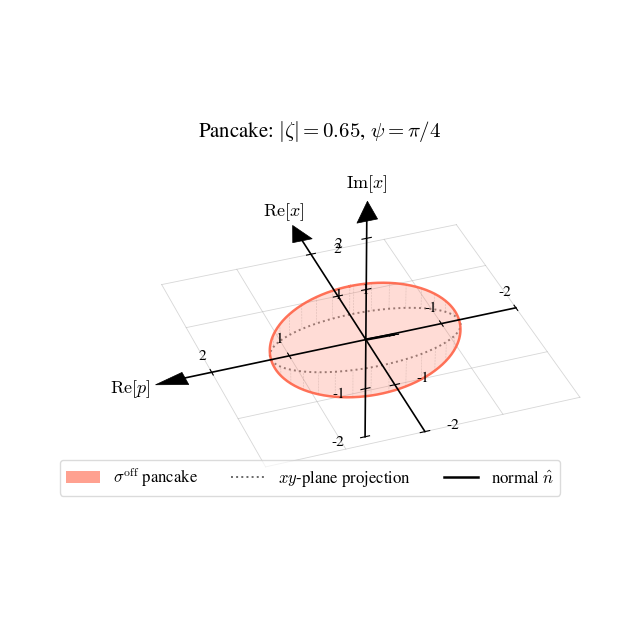

In [31]:
# Physical parameters
theta_Delta = np.pi / 6   # branching angle θ_Δ
s_param     = 3.0          # squeezing ratio s

zeta_val = zeta_from_params(theta_Delta, s_param)
psi_val  = np.pi / 4       # tilt angle ψ = 45°

print(f"|ζ|  = {zeta_val:.4f}   (ζ² = {zeta_val**2:.4f})")
print(f"Semi-axes: √|ζ| = {np.sqrt(zeta_val):.4f},  1/√|ζ| = {1/np.sqrt(zeta_val):.4f}")
print(f"σ_off =\n{sigma_off_matrix(zeta_val, psi_val)}")

# azim=160, elev=35: nearly face-on view so the pancake is clearly visible
fig, ax = Plot_Pancake_3D(
    zeta_val, psi_val,
    sym_lim=2.0, elev=35, azim=160, color='tomato',
    title=rf'Pancake: $|\zeta|={zeta_val:.2f}$, $\psi = \pi/4$')
plt.show()
